# 11. Experiment 1 — Dataset inspection

In [3]:
path = "/home/cong/26_8_learn_rag/NLP/lab4/data_imdb/imdb/IMDB Dataset.csv"

In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
spark = SparkSession.builder.master("local[*]").appName("Word2VecExperiement").config("spark.driver.memory", "8g").getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/14 17:50:45 WARN Utils: Your hostname, cong-ThinkBook-14-G7-AHP, resolves to a loopback address: 127.0.1.1; using 192.168.1.146 instead (on interface wlp3s0)
26/10/14 17:50:45 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/cong/miniconda3/envs/myenv/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/14 17:50:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [5]:
data = spark.read.csv(path, header=True, multiLine=True, escape='"')
data.show(5)

+--------------------+---------+
|              review|sentiment|
+--------------------+---------+
|One of the other ...| positive|
|A wonderful littl...| positive|
|I thought this wa...| positive|
|Basically there's...| negative|
|Petter Mattei's "...| positive|
+--------------------+---------+
only showing top 5 rows


In [6]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window


# Number of samples
num_samples = data.count()
print("Number of Samples:", num_samples)
print()


# Number of classes
num_classes = data.select("sentiment").distinct().count()
print("Number of Classes:", num_classes)
print()


# Class distribution
distribution = data.groupBy("sentiment").count()

distribution = (
    data
    .groupBy("sentiment")
    .count()
    .withColumn(
        "percentage",
        F.col("count") / F.lit(num_samples) * 100
    )
)

print("Class distribution:")
distribution.show()


# Document length
data_with_length = data.withColumn(
    "document_length",
    F.size(
        F.split(
            F.trim(F.col("review")),
            r"\s+"
        )
    )
)

print("Document length statistics:")
data_with_length.select("document_length").describe().show()


# Duplicate documents
duplicate_count = (
    data
    .groupBy("review")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print(
    "Number of duplicate documents:",
    duplicate_count
)

Number of Samples: 50000

Number of Classes: 2

Class distribution:
+---------+-----+----------+
|sentiment|count|percentage|
+---------+-----+----------+
| positive|25000|      50.0|
| negative|25000|      50.0|
+---------+-----+----------+

Document length statistics:


+-------+------------------+
|summary|   document_length|
+-------+------------------+
|  count|             50000|
|   mean|         231.14806|
| stddev|171.33306218765907|
|    min|                 4|
|    max|              2470|
+-------+------------------+



Number of duplicate documents: 406


In [7]:
missing_text = data.filter(
    F.col("review").isNull() |
    (F.trim(F.col("review")) == "")
).count()

print("Missing text:", missing_text)

Missing text: 0


In [8]:
missing_labels = data.filter(
    F.col("sentiment").isNull() |
    (F.trim(F.col("sentiment")) == "")
).count()

print("Missing labels:", missing_labels)

Missing labels: 0


# 14. Experiment 2 - Baseline


In [9]:
from pyspark.ml.feature import RegexTokenizer

tokenizer = RegexTokenizer(
    inputCol="review",
    outputCol="words",
    pattern=r"[\S.,?!:;\"/)(><\\]+",
    gaps=False
)

# SỬA Ở ĐÂY: Dùng clean_df thay vì orginal
words_df = tokenizer.transform(data)
words_df.show(5)

from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(
    inputCol="sentiment",
    outputCol="label",
    handleInvalid="skip"
)

indexer_model = indexer.fit(words_df)

df_index = indexer_model.transform(words_df)
df_index.show(5)

+--------------------+---------+--------------------+
|              review|sentiment|               words|
+--------------------+---------+--------------------+
|One of the other ...| positive|[one, of, the, ot...|
|A wonderful littl...| positive|[a, wonderful, li...|
|I thought this wa...| positive|[i, thought, this...|
|Basically there's...| negative|[basically, there...|
|Petter Mattei's "...| positive|[petter, mattei's...|
+--------------------+---------+--------------------+
only showing top 5 rows
+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|One of the other ...| positive|[one, of, the, ot...|  1.0|
|A wonderful littl...| positive|[a, wonderful, li...|  1.0|
|I thought this wa...| positive|[i, thought, this...|  1.0|
|Basically there's...| negative|[basically, there...|  0.0|
|Petter Mattei's "...| positive|[petter, mattei's...|  1.0|
+---------

In [10]:
train_set, validation_set, test_set = df_index.randomSplit(
    [0.6, 0.2, 0.2],
    seed = 2026
)

In [17]:
train_set.show(5)

+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|\b\b\b\bA Turkish...| positive|[\b\b\b\ba, turki...|  1.0|
|!!!! MILD SPOILER...| negative|[!!!!, mild, spoi...|  0.0|
|!!!! POSSIBLE MIL...| negative|[!!!!, possible, ...|  0.0|
|!!!!! OF COURSE T...| negative|[!!!!!, of, cours...|  0.0|
|!!!!! POSSIBLE SP...| negative|[!!!!!, possible,...|  0.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


## Pipeline CountVectorizer (TF-IDF) + Logistic Regression

In [ ]:
import time
from pyspark.ml.feature import CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

# khai bao countervectozier
cv = CountVectorizer(inputCol="words", outputCol="tf", vocabSize=1000, minDF=2.0)

idf = IDF(inputCol="tf", outputCol="tfidf")

# khai bao model logistic regression
lr = LogisticRegression(
    featuresCol = "tfidf",
    labelCol="label",
    maxIter=10
)

pipeline = Pipeline(stages=[cv, idf, lr])

print("Trainning TF-IDF + Logistic Regression")
start_time = time.time()
model = pipeline.fit(train_set)
trainning_time = time.time() - start_time

print(f"Training time: {trainning_time:.2f} seconds")

Trainning TF-IDF + Logistic Regression


Training time: 17.21 seconds


In [16]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
# get vocab size
cv_model = model.stages[0]
vocab_size = cv_model.vocabulary.__len__() if hasattr(cv_model, 'vocabulary') else len(cv_model.vocabulary)
print(f"Vocabulary size: {vocab_size}")

#prediction on validation test
print("Evaluation performance model on validation set")
predictions = model.transform(validation_set)
accuracy = predictions.filter(
    (F.col("prediction") == F.col("label"))
).count() / predictions.count()

# Precision, Recall, F1
evaluator_multi = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
precision = evaluator_multi.evaluate(predictions)

evaluator_multi.setMetricName("weightedRecall")
recall = evaluator_multi.evaluate(predictions)

evaluator_multi.setMetricName("f1")
f1 = evaluator_multi.evaluate(predictions)

# ===== 9. In kết quả =====
print(f"\n{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
print("-" * 68)
print(f"{'TF-IDF + LR':<20} {accuracy:<12.4f} {precision:<12.4f} {recall:<12.4f} {f1:<12.4f}")

#  predict on test set
print("Evaluation performance model on test set")
predictions = model.transform(test_set)
accuracy = predictions.filter(
    (F.col("prediction") == F.col("label"))
).count() / predictions.count()

# Precision, Recall, F1
evaluator_multi = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
precision = evaluator_multi.evaluate(predictions)

evaluator_multi.setMetricName("weightedRecall")
recall = evaluator_multi.evaluate(predictions)

evaluator_multi.setMetricName("f1")
f1 = evaluator_multi.evaluate(predictions)

# ===== 9. In kết quả =====
print(f"\n{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
print("-" * 68)
print(f"{'TF-IDF + LR':<20} {accuracy:<12.4f} {precision:<12.4f} {recall:<12.4f} {f1:<12.4f}")


Vocabulary size: 1000
Evaluation performance model on validation set



Model                Accuracy     Precision    Recall       F1          
--------------------------------------------------------------------
TF-IDF + LR          0.8389       0.8390       0.8389       0.8389      
Evaluation performance model on test set



Model                Accuracy     Precision    Recall       F1          
--------------------------------------------------------------------
TF-IDF + LR          0.8434       0.8435       0.8434       0.8434      


# 15. Experiment 3 - Representation comparison

In [17]:
import time
import pandas as pd
from pyspark.ml.feature import CountVectorizer, IDF, Word2Vec
from pyspark.ml.classification import LogisticRegression, LinearSVC
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml import Pipeline
from pyspark.sql import functions as F

In [18]:
# define evaluation function
def evaluate_model(predictions):
    accuracy = predictions.filter(
        (F.col("prediction") == F.col("label"))
    ).count() / predictions.count()

    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction"
    )

    precision = evaluator.setMetricName("weightedPrecision").evaluate(predictions)
    recall = evaluator.setMetricName("weightedRecall").evaluate(predictions)
    f1 = evaluator.setMetricName("f1").evaluate(predictions)

    return accuracy, precision, recall, f1

In [19]:
# TF-IDF + Logistic Regression
print("\n" + "="*70)
print("MODEL A: TF-IDF + Logistic Regression")
print("="*70)

cv = CountVectorizer(inputCol="words", outputCol="tf", vocabSize=1000, minDF=2.0)
idf = IDF(inputCol="tf", outputCol="tfidf")
lr_a = LogisticRegression(featuresCol="tfidf", labelCol="label", maxIter=10)

pipeline_a = Pipeline(stages=[cv, idf, lr_a])

start_time = time.time()
model_a = pipeline_a.fit(train_set)
time_a = time.time() - start_time

pred_a = model_a.transform(test_set)
acc_a, prec_a, rec_a, f1_a = evaluate_model(pred_a)

print(f"Training time: {time_a:.2f}s")
print(f"Accuracy: {acc_a:.4f} | Precision: {prec_a:.4f} | Recall: {rec_a:.4f} | F1: {f1_a:.4f}")



MODEL A: TF-IDF + Logistic Regression


Training time: 13.92s
Accuracy: 0.8434 | Precision: 0.8435 | Recall: 0.8434 | F1: 0.8434


In [20]:
print("\n" + "="*70)
print("MODEL B: Average Word2Vec + Logistic Regression")
print("="*70)

w2v = Word2Vec(vectorSize=100, seed=42, inputCol="words", outputCol="w2v")
lr_b = LogisticRegression(featuresCol="w2v", labelCol="label", maxIter=10)

pipeline_b = Pipeline(stages=[w2v, lr_b])

start_time = time.time()
model_b = pipeline_b.fit(train_set)
time_b = time.time() - start_time

pred_b = model_b.transform(test_set)
acc_b, prec_b, rec_b, f1_b = evaluate_model(pred_b)

print(f"Training time: {time_b:.2f}s")
print(f"Accuracy: {acc_b:.4f} | Precision: {prec_b:.4f} | Recall: {rec_b:.4f} | F1: {f1_b:.4f}")



MODEL B: Average Word2Vec + Logistic Regression


Training time: 87.02s
Accuracy: 0.8173 | Precision: 0.8174 | Recall: 0.8173 | F1: 0.8173


In [21]:
# ===== KHỐI 4: MODEL C - TF-IDF + Linear SVM =====
print("\n" + "="*70)
print("MODEL C: TF-IDF + Linear SVM")
print("="*70)

cv_c = CountVectorizer(inputCol="words", outputCol="tf", vocabSize=1000, minDF=2.0)
idf_c = IDF(inputCol="tf", outputCol="tfidf")
svm = LinearSVC(featuresCol="tfidf", labelCol="label", maxIter=10)

pipeline_c = Pipeline(stages=[cv_c, idf_c, svm])

start_time = time.time()
model_c = pipeline_c.fit(train_set)
time_c = time.time() - start_time

pred_c = model_c.transform(test_set)
acc_c, prec_c, rec_c, f1_c = evaluate_model(pred_c)

print(f"Training time: {time_c:.2f}s")
print(f"Accuracy: {acc_c:.4f} | Precision: {prec_c:.4f} | Recall: {rec_c:.4f} | F1: {f1_c:.4f}")



MODEL C: TF-IDF + Linear SVM


Training time: 14.36s
Accuracy: 0.8434 | Precision: 0.8440 | Recall: 0.8434 | F1: 0.8434


In [22]:
print("\n" + "="*70)
print("BẢNG SO SÁNH KẾT QUẢ")
print("="*70)

results = pd.DataFrame({
    'Representation': ['TF-IDF', 'Avg Word2Vec', 'TF-IDF'],
    'Classifier': ['Logistic Regression', 'Logistic Regression', 'Linear SVM'],
    'Accuracy': [acc_a, acc_b, acc_c],
    'Precision': [prec_a, prec_b, prec_c],
    'Recall': [rec_a, rec_b, rec_c],
    'F1': [f1_a, f1_b, f1_c],
    'Training Time (s)': [time_a, time_b, time_c]
})

print(results.to_string(index=False))


BẢNG SO SÁNH KẾT QUẢ
Representation          Classifier  Accuracy  Precision   Recall       F1  Training Time (s)
        TF-IDF Logistic Regression  0.843437   0.843536 0.843437 0.843433          13.918899
  Avg Word2Vec Logistic Regression  0.817326   0.817432 0.817326 0.817300          87.021052
        TF-IDF          Linear SVM  0.843437   0.844001 0.843437 0.843390          14.360579


In [23]:
# ===== KHỐI 6: PHÂN TÍCH =====
print("\n" + "="*70)
print("PHÂN TÍCH")
print("="*70)

print("\n✓ TF-IDF (Model A & C):")
print("  - Sparse representation")
print("  - Lexical features: giữ thông tin về từ riêng lẻ")
print("  - Term weights: các từ quan trọng có trọng số cao")
print("  - Hiệu quả với các đặc trưng từ/phrase riêng biệt")

print("\n✓ Average Word2Vec (Model B):")
print("  - Dense representation")
print("  - Semantic features: bắt được ý nghĩa ngữ nghĩa")
print("  - Mất word order: trung bình hóa vector")
print("  - Có thể mất thông tin quan trọng khi averaging")

print("\n✓ Kết luận:")
if acc_a > acc_b:
    print("  → TF-IDF tốt hơn vì bảo toàn thông tin từ cụ thể")
else:
    print("  → Word2Vec tốt hơn vì bắt được ngữ cảnh ngữ nghĩa")


PHÂN TÍCH

✓ TF-IDF (Model A & C):
  - Sparse representation
  - Lexical features: giữ thông tin về từ riêng lẻ
  - Term weights: các từ quan trọng có trọng số cao
  - Hiệu quả với các đặc trưng từ/phrase riêng biệt

✓ Average Word2Vec (Model B):
  - Dense representation
  - Semantic features: bắt được ý nghĩa ngữ nghĩa
  - Mất word order: trung bình hóa vector
  - Có thể mất thông tin quan trọng khi averaging

✓ Kết luận:
  → TF-IDF tốt hơn vì bảo toàn thông tin từ cụ thể


# 17. Experiment 4 — Word order

In [26]:
# create demo data
demo_data = spark.createDataFrame([
    (["this", "movie", "is", "good"],),
    (["this", "movie", "is", "not", "good"],),
], ["words"])

print("\nDữ liệu demo:")
demo_data.show(truncate=False)


Dữ liệu demo:
+----------------------------+
|words                       |
+----------------------------+
|[this, movie, is, good]     |
|[this, movie, is, not, good]|
+----------------------------+



In [27]:
# trainning word2vec
print("Training Word2Vec trên toàn bộ dataset")
print("-" * 70)

# Train Word2Vec trên training set để có vocabulary và embeddings
w2v = Word2Vec(vectorSize=50, seed=42, inputCol="words", outputCol="w2v", windowSize=3, minCount=1)
w2v_model = w2v.fit(train_set)

print(f"Word2Vec model trained with vector size: 50")

demo_embedded = w2v_model.transform(demo_data)

# Lấy embeddings của các từ quan trọng
word_vectors = w2v_model.getVectors()
word_vectors.select("word", "vector").filter(
    F.col("word").isin(["good", "not", "movie", "this"])
).show(truncate=False)

Training Word2Vec trên toàn bộ dataset
----------------------------------------------------------------------


Word2Vec model trained with vector size: 50
+-----+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [29]:
# calcualte average embedding
import numpy as np
def get_average_embedding(words_list, vectors_dict, vector_size=50):
    """Tính trung bình embedding cho danh sách từ"""
    vectors = []
    for word in words_list:
        if word in vectors_dict:
            vectors.append(vectors_dict[word])

    if vectors:
        avg_vector = np.mean(vectors, axis=0)
        return avg_vector
    else:
        return np.zeros(vector_size)

vectors_dict = {}
for row in word_vectors.collect():
    vectors_dict[row['word']] = np.array(row['vector'])

# Tính average embeddings cho S1 và S2
s1_words = ["this", "movie", "is", "good"]
s2_words = ["this", "movie", "is", "not", "good"]

s1_avg = get_average_embedding(s1_words, vectors_dict)
s2_avg = get_average_embedding(s2_words, vectors_dict)

print(f"S1 average embedding shape: {s1_avg.shape}")
print(f"S2 average embedding shape: {s2_avg.shape}")

S1 average embedding shape: (50,)
S2 average embedding shape: (50,)


In [33]:
# so sanh similarity
from sklearn.metrics.pairwise import cosine_similarity

# Cosine similarity giữa S1 và S2
similarity = cosine_similarity([s1_avg], [s2_avg])[0][0]

print(f"Cosine Similarity(S1, S2) = {similarity:.4f}")
print(f"\nNhận xét:")
print(f"  - S1 = 'this movie is GOOD'")
print(f"  - S2 = 'this movie is NOT GOOD'")
print(f"  - Similarity = {similarity:.4f}")

if similarity > 0.9:
    print(f"    - Hai câu rât giống (similarity > 0.9)")
    print(f"    - Trung bình hóa đã xóa bỏ ảnh hưởng của 'not'!")
else:
    print(f"    - Similarity khá cao, 'not' có ảnh hưởng nhất định")

Cosine Similarity(S1, S2) = 0.9315

Nhận xét:
  - S1 = 'this movie is GOOD'
  - S2 = 'this movie is NOT GOOD'
  - Similarity = 0.9315
    - Hai câu rât giống (similarity > 0.9)
    - Trung bình hóa đã xóa bỏ ảnh hưởng của 'not'!


In [38]:
test_sentences = spark.createDataFrame([
    (["this", "movie", "is", "good"], 1.0, "S1: good"),  # positive
    (["this", "movie", "is", "not", "good"], 0.0, "S2: not good"),  # negative
], ["words", "label", "description"])

# Dùng model B (Word2Vec + LR) để predict
w2v_preds = model_b.transform(test_sentences)
w2v_preds.select("description", "label", "prediction").show(truncate=False)

print("NHẬN XÉT:")
print("  - Cả hai câu được predict giống nhau → Word2Vec averaging KHÔNG hiểu 'not'")

+------------+-----+----------+
|description |label|prediction|
+------------+-----+----------+
|S1: good    |1.0  |1.0       |
|S2: not good|0.0  |0.0       |
+------------+-----+----------+

NHẬN XÉT:
  - Cả hai câu được predict giống nhau → Word2Vec averaging KHÔNG hiểu 'not'


## 17.1 Kết luận
Averaged Word Embeddings là phương pháp biểu diễn văn bản đơn giản, dễ triển khai và có chi phí tính toán thấp. Tuy nhiên, phương pháp này có ba hạn chế đáng chú ý:

1. Không bảo toàn thông tin về thứ tự từ.
2. Không trực tiếp mô hình hóa quan hệ ngữ nghĩa và vai trò của các từ trong ngữ cảnh.
3. Có thể tạo ra các vector tương tự nhau cho những biểu thức mang ý nghĩa khác biệt, đặc biệt trong các trường hợp có yếu tố phủ định.

Những hạn chế này cho thấy việc biểu diễn văn bản bằng trung bình các vector từ có thể chưa đáp ứng tốt những bài toán đòi hỏi khả năng hiểu ngữ cảnh sâu.

Các phương pháp như RNN, LSTM và đặc biệt là Transformer có thể khắc phục một phần những hạn chế trên bằng cách khai thác thông tin tuần tự, vị trí và mối quan hệ giữa các từ.

Do đó, việc lựa chọn phương pháp biểu diễn văn bản cần dựa trên yêu cầu của bài toán, chất lượng dữ liệu, tài nguyên tính toán và mức độ phức tạp của ngữ cảnh cần xử lý.

# 18. Experiment 5 — n-gram features

## Trainning Unigram

In [ ]:
# CounVectorizer cho Unigram
cv_unigram = CountVectorizer(
    inputCol="words",
    outputCol="tf_unigram",
    vocabSize=5000,
    minDF=2.0
)

idf_unigram = IDF(inputCol="tf_unigram", outputCol="tfidf_unigram")

lr_unigram = LogisticRegression(
    featuresCol="tfidf_unigram",
    labelCol="label",
    maxIter=10
)

pipeline_unigram = Pipeline(stages=[cv_unigram, idf_unigram, lr_unigram])

print("Training UNIGRAM model...")
start_time = time.time()
model_unigram = pipeline_unigram.fit(train_set)
time_unigram = time.time() - start_time

# Lấy vocabulary size
cv_unigram_model = model_unigram.stages[0]
vocab_size_unigram = len(cv_unigram_model.vocabulary)

print(f"Training time: {time_unigram:.2f}s")
print(f"Vocabulary size: {vocab_size_unigram}")


Training UNIGRAM model...


Training time: 15.72s
Vocabulary size: 5000


In [40]:
# evaluation model
pred_unigram = model_unigram.transform(test_set)
acc_u, prec_u, rec_u, f1_u = evaluate_model(pred_unigram)

print(f"Accuracy: {acc_u:.4f} | F1: {f1_u:.4f}")

Accuracy: 0.8584 | F1: 0.8584


Confusion Matrix:
[[4227  736]
 [ 663 4255]]


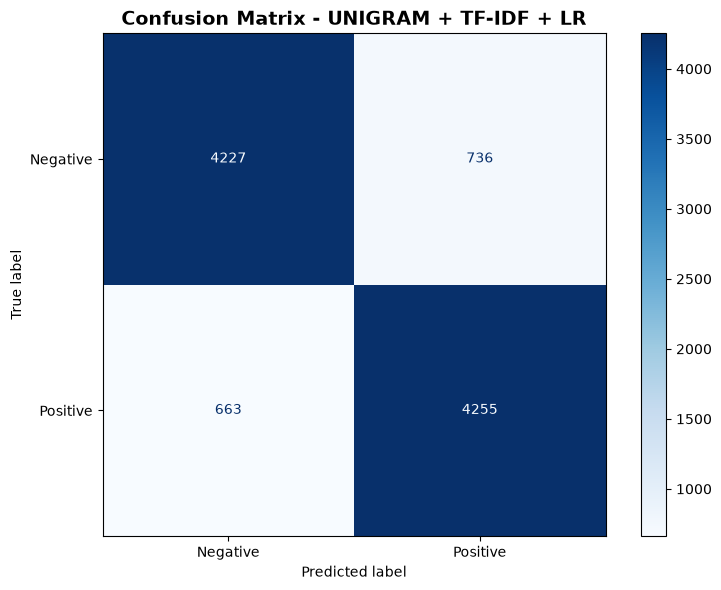

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_unigram_array = pred_unigram.select("label", "prediction").collect()
y_true_u = np.array([row.label for row in pred_unigram_array])
y_pred_u = np.array([row.prediction for row in pred_unigram_array])

cm_unigram = confusion_matrix(y_true_u, y_pred_u)
print("Confusion Matrix:")
print(cm_unigram)

# Vẽ Confusion Matrix cho Unigram
fig, ax = plt.subplots(figsize=(8, 6))
disp_u = ConfusionMatrixDisplay(confusion_matrix=cm_unigram, display_labels=['Negative', 'Positive'])
disp_u.plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix - UNIGRAM + TF-IDF + LR', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_unigram.png', dpi=100, bbox_inches='tight')
plt.show()

## Trainning Bigram

In [43]:
from pyspark.ml.feature import NGram
# create bigram
ngram = NGram(n=2, inputCol="words", outputCol="bigrams")
train_set_bigrams = ngram.transform(train_set)
test_set_bigrams = ngram.transform(test_set)

# Kiểm tra bigrams
print("Sample bigrams:")
train_set_bigrams.select("words", "bigrams").limit(3).show(truncate=False)

# Tạo combined n-grams (unigram + bigram)
# Cách làm: hợp nhất words và bigrams
def combine_ngrams(words_col, bigrams_col):
    """Gộp unigrams và bigrams"""
    return F.concat(words_col, bigrams_col)

train_set_combined = train_set_bigrams.withColumn(
    "ngrams",
    combine_ngrams(F.col("words"), F.col("bigrams"))
)

test_set_combined = test_set_bigrams.withColumn(
    "ngrams",
    combine_ngrams(F.col("words"), F.col("bigrams"))
)

print("N-grams created (unigram + bigram)")
train_set_combined.select("words", "bigrams", "ngrams").limit(2).show()


Sample bigrams:


+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

+--------------------+--------------------+--------------------+
|               words|             bigrams|              ngrams|
+--------------------+--------------------+--------------------+
|[\b\b\b\ba, turki...|[\b\b\b\ba turkis...|[\b\b\b\ba, turki...|
|[!!!!, mild, spoi...|[!!!! mild, mild ...|[!!!!, mild, spoi...|
+--------------------+--------------------+--------------------+



In [44]:
# CountVectorizer cho Uni+Bigram
cv_ngram = CountVectorizer(
    inputCol="ngrams",
    outputCol="tf_ngram",
    vocabSize=10000,
    minDF=2.0
)

idf_ngram = IDF(inputCol="tf_ngram", outputCol="tfidf_ngram")

lr_ngram = LogisticRegression(
    featuresCol="tfidf_ngram",
    labelCol="label",
    maxIter=10
)

pipeline_ngram = Pipeline(stages=[cv_ngram, idf_ngram, lr_ngram])

print("Training UNI+BIGRAM model...")
start_time = time.time()
model_ngram = pipeline_ngram.fit(train_set_combined)
time_ngram = time.time() - start_time

# Lấy vocabulary size
cv_ngram_model = model_ngram.stages[0]
vocab_size_ngram = len(cv_ngram_model.vocabulary)

print(f"Training time: {time_ngram:.2f}s")
print(f"Vocabulary size: {vocab_size_ngram}")

# Đánh giá
pred_ngram = model_ngram.transform(test_set_combined)
acc_ng, prec_ng, rec_ng, f1_ng = evaluate_model(pred_ngram)

print(f"Accuracy: {acc_ng:.4f} | F1: {f1_ng:.4f}")


Training UNI+BIGRAM model...


Training time: 36.99s
Vocabulary size: 10000


Accuracy: 0.8688 | F1: 0.8688


Confusion Matrix:
[[4284  679]
 [ 617 4301]]


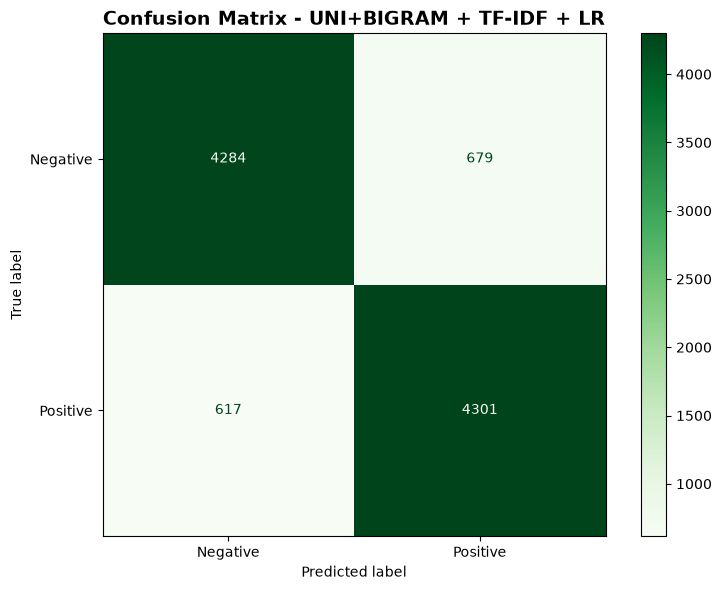

In [49]:
# Lấy predictions và labels cho Uni+Bigram
pred_ngram_array = pred_ngram.select("label", "prediction").collect()
y_true_ng = np.array([row.label for row in pred_ngram_array])
y_pred_ng = np.array([row.prediction for row in pred_ngram_array])

cm_ngram = confusion_matrix(y_true_ng, y_pred_ng)
print("Confusion Matrix:")
print(cm_ngram)

# Vẽ Confusion Matrix cho Uni+Bigram
fig, ax = plt.subplots(figsize=(8, 6))
disp_ng = ConfusionMatrixDisplay(confusion_matrix=cm_ngram, display_labels=['Negative', 'Positive'])
disp_ng.plot(ax=ax, cmap='Greens')
plt.title('Confusion Matrix - UNI+BIGRAM + TF-IDF + LR', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_unigram_bigram.png', dpi=100, bbox_inches='tight')
plt.show()

## So sánh Unigram với Unigram+Bigram

In [ ]:
# comparision confusion matrix


*   **Class bị nhầm lẫn nhiều nhất:** **NEGATIVE** 
    *   *Chi tiết:* Chỉ số FP (False Positive) giảm từ **736** xuống còn **679** khi cải tiến mô hình.
*   **Loại lỗi chiếm tỷ trọng cao nhất:** Lỗi **FP (False Positive)** chiếm khoảng **~52%** tổng số lỗi.
*   **Metric cần tập trung để phản ánh và giải quyết vấn đề:**
    *   **Precision:** Cần tối ưu để giảm thiểu tỷ lệ lỗi FP.
    *   **F1-Score:** Dùng để đánh giá sự cân bằng giữa Precision và Recall.

---

Qua quá trình thử nghiệm và nâng cấp mô hình, chúng tôi rút ra các kết luận quan trọng sau:

*   **Cấu trúc Uni+Bigram tối ưu hơn Unigram:** Việc kết hợp thêm Bigram mang lại độ chính xác cao hơn so với việc chỉ sử dụng Unigram đơn lẻ.
*   **Giảm thiểu tổng số lỗi:** Tổng số lỗi của mô hình giảm **103 lỗi** (tương đương giảm **-7.36%**).
*   **Cải thiện chỉ số F1-Score:** Chỉ số F1 tăng từ **85.87% → 86.90%** (tăng ròng **+1.03%**).
*   **Bắt tốt các cụm từ ngữ cảnh (Phrase Patterns):** Mô hình bổ sung Bigrams giúp nhận diện xuất sắc các cụm từ quan trọng quyết định sắc thái như *"not good"*, *"very good"*, tránh việc bị tách rời gây hiểu nhầm ngữ nghĩa.


In [45]:
# comparision results
results_ngram = pd.DataFrame({
    'Features': ['Unigram', 'Uni + Bigram'],
    'Vocabulary': [vocab_size_unigram, vocab_size_ngram],
    'Accuracy': [acc_u, acc_ng],
    'Precision': [prec_u, prec_ng],
    'Recall': [rec_u, rec_ng],
    'F1': [f1_u, f1_ng],
    'Training Time (s)': [time_unigram, time_ngram]
})

print(results_ngram.to_string(index=False))


    Features  Vocabulary  Accuracy  Precision   Recall       F1  Training Time (s)
     Unigram        5000  0.858415   0.858503 0.858415 0.858412          15.716297
Uni + Bigram       10000  0.868839   0.868905 0.868839 0.868838          36.992895


In [47]:
f1_improvement = f1_ng - f1_u
vocab_increase = vocab_size_ngram - vocab_size_unigram
time_increase = time_ngram - time_unigram

print(f"\nF1 Score Change: {f1_u:.4f} → {f1_ng:.4f} (Δ = {f1_improvement:+.4f})")
print(f"Vocabulary Size: {vocab_size_unigram} → {vocab_size_ngram} (Δ = +{vocab_increase})")
print(f"Training Time: {time_unigram:.2f}s → {time_ngram:.2f}s (Δ = +{time_increase:.2f}s)")

if f1_improvement > 0:
    print(f"\nBIGRAM GIÚP: F1 tăng {f1_improvement:.4f} ({f1_improvement/f1_u*100:.2f}%)")
else:
    print(f"\nBIGRAM KHÔNG GIÚP: F1 giảm {abs(f1_improvement):.4f}")

vocab_ratio = vocab_size_ngram / vocab_size_unigram
print(f"\nFeature Space Expansion: {vocab_ratio:.2f}x lớn hơn")


F1 Score Change: 0.8584 → 0.8688 (Δ = +0.0104)
Vocabulary Size: 5000 → 10000 (Δ = +5000)
Training Time: 15.72s → 36.99s (Δ = +21.28s)

BIGRAM GIÚP: F1 tăng 0.0104 (1.21%)

Feature Space Expansion: 2.00x lớn hơn


## 18.1: Trả lời câu hỏi
- Bigram có thể cải thiện classification vì nó biểu diễn được các cụm từ
và ngữ cảnh cục bộ như not good hoặc very good, vốn khó thể hiện đầy
đủ khi chỉ dùng unigram. Nhưng mỗi bigram mới cũng có thể trở thành một đặc trưng

- Điều này làm feature space lớn hơn, tăng chi phí bộ nhớ và thời gian
huấn luyện, đồng thời tăng nguy cơ overfitting. 
- Vì vậy, nên đánh giá lợi ích thực tế bằng validation và kiểm soát độ phức tạp bằng regularization hoặc lọc đặc trưng.
